# DSL Query Generator: дообучение Qwen3-4B переводу с русского на ECQL

Малая модель **Qwen3-4B-Instruct-2507** (4-bit) дообучена LoRA-адаптером переводить запросы
на русском языке во внутренний язык запросов ECQL вымышленной компании «E-Corp».

* Код и данные: [https://github.com/AlexIntellySoft/llm-7](https://github.com/AlexIntellySoft/llm-7)
* Ноутбук обучения в Colab: [`notebooks/train_colab.ipynb`](https://colab.research.google.com/github/AlexIntellySoft/llm-7/blob/main/notebooks/train_colab.ipynb)
* Веса адаптеров: [r=16](https://huggingface.co/Alex-Popov/qwen3-4b-ecql-lora-r16) (основной) и [r=8](https://huggingface.co/Alex-Popov/qwen3-4b-ecql-lora-r8)
* Метрики и ответы модели на тестовой выборке: `outputs/metrics.json`,
  `outputs/predictions_r16.jsonl`, `outputs/predictions_r8.jsonl`

Этот ноутбук ничего не обучает. Он читает результаты Colab-прогона из `outputs/` и
выполняется без GPU.

In [1]:
import json, sys
from collections import Counter
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.ecql import ENTITIES, conditions, parse
from src.evaluate import METRIC_NAMES

def jsonl(p): return [json.loads(l) for l in (ROOT / p).read_text(encoding="utf-8").splitlines() if l]
pd.set_option("display.max_colwidth", None)
data, train, test = jsonl("data/ecql_dataset.jsonl"), jsonl("data/train.jsonl"), jsonl("data/test.jsonl")
metrics = json.loads((ROOT / "outputs/metrics.json").read_text())
preds = {n: jsonl(f"outputs/predictions_{n}.jsonl") for n in ("r8", "r16")}
hist = {n: json.loads((ROOT / f"outputs/log_history_{n}.json").read_text()) for n in ("r8", "r16")}

## 1. Спецификация ECQL и датасет

Правила задания: `FETCH`, сущность в `[]`, поля с `@`, операторы `IS / NOT / ABOVE / BELOW`,
связки `&& / ||`, формат `AS JSON / TABLE / LIST`. Без двух договорённостей датасет не сделать
согласованным, поэтому я их добавил:

* условия начинаются с `WHERE` (так в примере из задания);
* «вложенность» означает скобки: при смешении `&&` и `||` скобки ставятся всегда.

Ещё для каждой сущности задана **схема**: набор полей и их типы. Строковые значения пишутся
по-английски («Москва» → `'Moscow'`, «заморожен» → `'on_hold'`), числа полностью
(«2,5 млн» → `2500000`). Полная схема и промпт учителю: `docs/teacher_prompt.md`.

**Модель-учитель — Claude.** Ключ YandexGPT из прошлых заданий истёк. Каждый эталон
автоматически проверен парсером `src/ecql.py`: грамматика, поля сущности, типы значений,
отсутствие SQL. Разбиение 80/20 стратифицировано по сложности и сущности.

In [2]:
df = pd.DataFrame(data)
order = ["all", "simple", "and", "or", "nested"]
tab = pd.crosstab(df["entity"], df["level"])[order]
tab.loc["итого"] = tab.sum()
tab["итого"] = tab.sum(axis=1)
print(f"всего {len(data)} пар: train {len(train)}, test {len(test)}")
print("уровни: all — без условий, simple — одно условие, and — 2–3 через &&, or — через ||, nested — && и || со скобками")
tab

всего 184 пар: train 148, test 36
уровни: all — без условий, simple — одно условие, and — 2–3 через &&, or — через ||, nested — && и || со скобками


level,all,simple,and,or,nested,итого
entity,,,,,,
DEALS,3,17,10,4,7,41
EMPLOYEES,3,22,18,6,10,59
INVENTORY,2,14,12,5,6,39
PROJECTS,3,18,13,5,6,45
итого,11,71,53,20,29,184


In [3]:
ops = Counter(c.op for r in data for c in conditions(parse(r["output"]).where))
fmts = Counter(parse(r["output"]).fmt or "без AS" for r in data)
print("операторы:", dict(ops))
print("формат вывода:", dict(fmts))
print("поля:", {e: len(f) for e, f in ENTITIES.items()})
df.groupby("level").head(1)[["level", "input", "output"]]

операторы: {'IS': 216, 'ABOVE': 56, 'BELOW': 41, 'NOT': 27}
формат вывода: {'без AS': 132, 'TABLE': 19, 'JSON': 20, 'LIST': 13}
поля: {'EMPLOYEES': 8, 'PROJECTS': 8, 'INVENTORY': 6, 'DEALS': 7}


,level,input,output
0,simple,Покажи всех сотрудников из Казани,FETCH [EMPLOYEES] WHERE @city IS 'Kazan'
8,all,Выгрузи всех сотрудников в JSON,FETCH [EMPLOYEES] AS JSON
16,and,Найди всех сотрудников из Москвы с зарплатой выше 150000,FETCH [EMPLOYEES] WHERE @city IS 'Moscow' && @salary ABOVE 150000
27,or,Покажи сотрудников из Казани или Самары,FETCH [EMPLOYEES] WHERE @city IS 'Kazan' || @city IS 'Samara'
32,nested,Разработчики из Москвы или Санкт-Петербурга,FETCH [EMPLOYEES] WHERE @position IS 'Developer' && (@city IS 'Moscow' || @city IS 'Saint Petersburg')


## 2. Базовая модель и LoRA

| параметр | значение | почему |
| --- | --- | --- |
| модель | `Qwen/Qwen3-4B-Instruct-2507` | из рекомендованных в задании; в 4-bit занимает ≈3 ГБ на T4; instruct-версия без «размышлений» `<think>`, хорошо понимает русский |
| квантование | 4-bit NF4 + double quant, вычисления в fp16 | QLoRA-схема из задания; T4 не поддерживает bf16 |
| `r` | **16** (и контрольный прогон 8) | задача узкая (≈30 полей, 4 оператора), а данных мало (148 примеров). r 8–16 хватает, чтобы выучить формат; больший ранг на таком объёме скорее запомнит примеры, чем обобщит |
| `lora_alpha` | **2·r** (32 и 16) | стандартный масштаб alpha/r = 2. Он одинаков в обоих прогонах, поэтому они различаются только рангом |
| целевые модули | `q_proj, k_proj, v_proj, o_proj` | рекомендация задания. Перевод здесь — это в основном «какое слово запроса соответствует какому полю и оператору», а такие связи задаёт внимание. MLP не трогаем, чтобы адаптер остался маленьким |
| `lora_dropout` | 0.05 | лёгкая регуляризация при 148 примерах |
| обучаемых параметров | 5.9 млн (r=16), 2.9 млн (r=8) | 0.15% и 0.07% от 4 млрд |

Loss считается **только по ответу** (формат prompt/completion в `SFTTrainer`). Модель учится
писать ECQL, а не повторять русский запрос.

## 3. Дообучение

`trl.SFTTrainer`: lr 2e-4 (косинусное расписание, 3 шага прогрева), 3 эпохи, батч 2 ×
накопление градиента 4 = 8, `max_length` 256 (самый длинный пример — 113 токенов), fp16.
Всего 57 шагов, на T4 около 3 минут на прогон.

Loss на тестовой выборке считался каждые 4 шага, только для наблюдения: в обучении она не
участвует и чекпоинт по ней не выбирался.

*Практическая деталь.* Для 4-bit модели `SFTTrainer` переводит веса LoRA в bfloat16
(рекомендация QLoRA для A100/H100). На T4 это роняет fp16-обучение ошибкой
`_amp_foreach_non_finite_check_and_unscale_cuda not implemented for 'BFloat16'`. Поэтому
после создания тренера обучаемые веса возвращаются в fp32 (`src/finetune.py`).

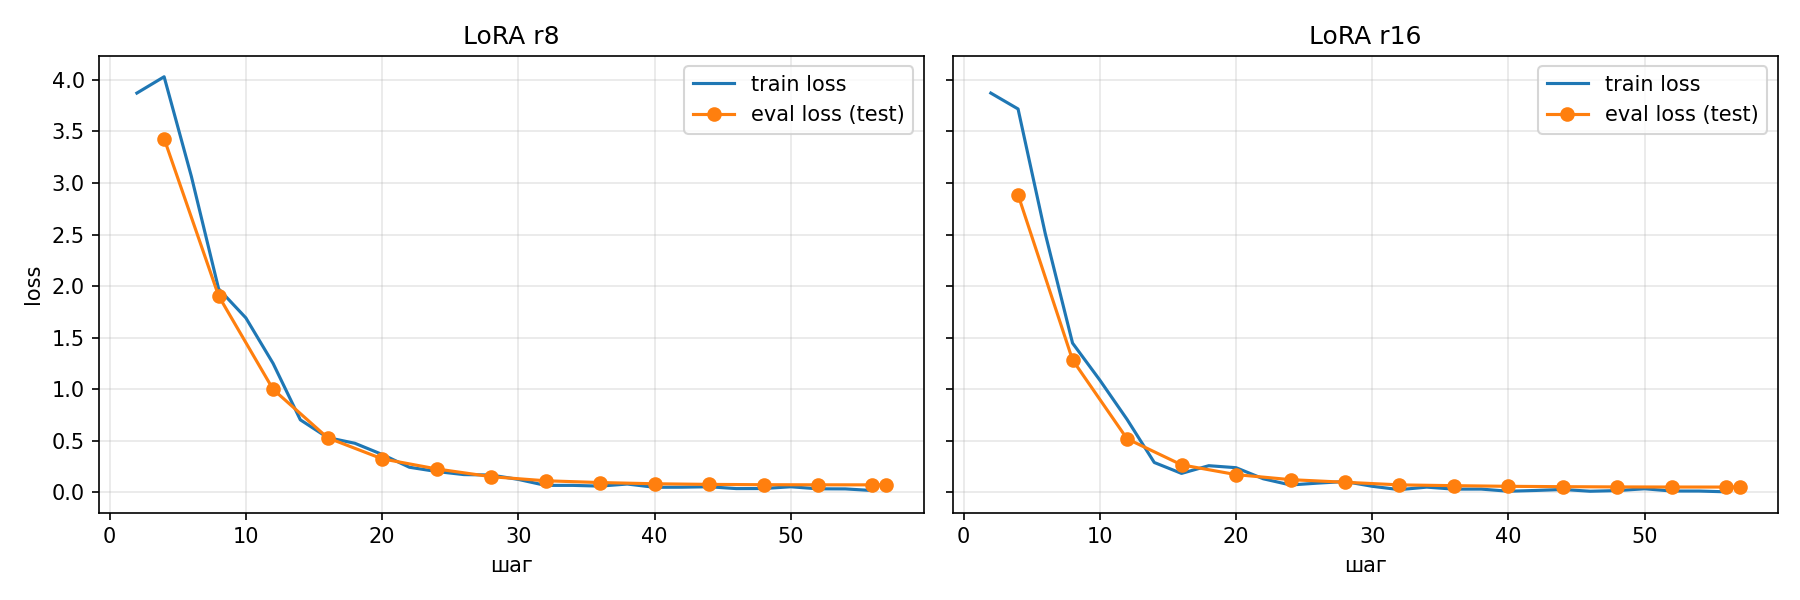

,"train loss, шаг 2","train loss, шаг 56","eval loss, шаг 4","eval loss, шаг 20","eval loss, шаг 40","eval loss, финал","время, мин"
адаптер,,,,,,,
r8,3.872,0.019,3.431,0.327,0.085,0.074,3.181
r16,3.872,0.006,2.886,0.173,0.060,0.053,3.110


In [4]:
display(Image(str(ROOT / "outputs/loss_curve.png")))
rows = []
for n, h in hist.items():
    tr = {x["step"]: x["loss"] for x in h if "loss" in x}
    ev = {x["step"]: x["eval_loss"] for x in h if "eval_loss" in x}
    run = next(x for x in h if "train_runtime" in x)
    rows.append({"адаптер": n, "train loss, шаг 2": tr[2], "train loss, шаг 56": tr[56],
                 "eval loss, шаг 4": ev[4], "eval loss, шаг 20": ev[20], "eval loss, шаг 40": ev[40],
                 "eval loss, финал": ev[max(ev)], "время, мин": run["train_runtime"] / 60})
pd.DataFrame(rows).set_index("адаптер").round(3)

Loss падает ровно, без скачков. Резкий спуск идёт первые ~15 шагов (одна эпоха ≈ 19 шагов):
модель выучивает каркас `FETCH [..] WHERE @.. AS ..`. Дальше идёт медленное уточнение значений.

Признаков переобучения нет. Loss на тесте всё время идёт вместе с train loss и до конца не
растёт. Последние ~10 шагов она стоит на месте (0.074 у r8, 0.053 у r16), так что 3 эпохи —
верхняя граница: дальше модель только запоминала бы обучающие примеры. У r=16 обе кривые
ниже на всём пути: больший ранг быстрее и глубже подгоняется под формат.

## 4. Тестирование на отложенной выборке

Оба адаптера подключены к **свежезагруженной** базовой модели (`PeftModel.from_pretrained`)
и прогнаны по 36 тестовым запросам, которых модель не видела. Генерация жадная.
Метрики (`src/evaluate.py`):

* **синтаксис:** ответ разбирается грамматикой ECQL (`@`, `[]`, `&&`/`||`, скобки, кавычки);
* **логика:** та же сущность, тот же формат `AS`, те же условия (поле, оператор, значение) и
  та же структура И/ИЛИ. Порядок операндов внутри `&&`/`||` не важен. Отдельно считается
  путаница `ABOVE`/`BELOW` (поле и значение верны, оператор нет);
* **галлюцинации:** в ответе есть элементы SQL (`SELECT`, `FROM`, `AND`, `OR`, `=`, `>`…).

In [5]:
groups = {
    "синтаксис": ["syntax_valid", "schema_valid"],
    "логика": ["entity_correct", "conditions_correct", "format_correct", "logic_correct", "exact_match"],
    "галлюцинации": ["sql_hallucination"],
}
rows = []
for g, keys in groups.items():
    for k in keys:
        rows.append({"критерий": g, "метрика": METRIC_NAMES[k],
                     **{n: f"{metrics[n][k]:.0%} ({round(metrics[n][k] * 36)}/36)" for n in ("r8", "r16")}})
rows.append({"критерий": "логика", "метрика": "перепутан ABOVE/BELOW или IS/NOT (условий)",
             **{n: str(metrics[n]["operator_errors_total"]) for n in ("r8", "r16")}})
pd.DataFrame(rows).set_index(["критерий", "метрика"])

r8  \
критерий     метрика                                                    
синтаксис    синтаксис корректен                         100% (36/36)   
             поля и типы есть в схеме                     89% (32/36)   
логика       верная сущность                             100% (36/36)   
             верные условия                               67% (24/36)   
             верный формат AS                             97% (35/36)   
             логически эквивалентен эталону               64% (23/36)   
             точное совпадение строки                     64% (23/36)   
галлюцинации есть элементы SQL                              0% (0/36)   
логика       перепутан ABOVE/BELOW или IS/NOT (условий)             0   

                                                                 r16  
критерий     метрика                                                  
синтаксис    синтаксис корректен                         94% (34/36)  
             поля и типы есть в схеме                    92% (33/36)  
логика       верная сущность                             94% (34/36)  
             верные условия                              75% (27/36)  
             верный формат AS                            92% (33/36)  
             логически эквивалентен эталону              72% (26/36)  
             точное совпадение строки                    69% (25/36)  
галлюцинации есть элементы SQL                             0% (0/36)  
логика       перепутан ABOVE/BELOW или IS/NOT (условий)            0

In [6]:
lvl = pd.DataFrame({n: pd.DataFrame(p).groupby("level")["logic_correct"].agg(lambda s: f"{s.sum()}/{len(s)}")
                    for n, p in preds.items()}).loc[order]
lvl.index.name = "логически верно по уровням"
lvl

,r8,r16
логически верно по уровням,,
all,1/2,1/2
simple,11/14,11/14
and,8/10,7/10
or,3/4,4/4
nested,0/6,3/6


### 5 примеров из тестовой выборки (адаптер r=16)

По одному запросу каждого уровня сложности плюс один ошибочный ответ.

In [7]:
p16 = preds["r16"]
pick = [next(r for r in p16 if r["level"] == l and r["logic_correct"]) for l in ("simple", "and", "or", "nested")]
pick.append(next(r for r in p16 if r["input"].startswith("Активные проекты Смирнова")))
pd.DataFrame([{"вход на русском": r["input"], "эталонный ECQL": r["reference"],
               "ответ модели": r["prediction"], "верно": "✅" if r["logic_correct"] else "❌"} for r in pick])

,вход на русском,эталонный ECQL,ответ модели,верно
0,Найди сотрудников с окладом меньше 60 тысяч,FETCH [EMPLOYEES] WHERE @salary BELOW 60000,FETCH [EMPLOYEES] WHERE @salary BELOW 60000,✅
1,"Сделки на переговорах с вероятностью меньше 30 процентов, в JSON",FETCH [DEALS] WHERE @stage IS 'negotiation' && @probability BELOW 30 AS JSON,FETCH [DEALS] WHERE @stage IS 'negotiation' && @probability BELOW 30 AS JSON,✅
2,Позиции со склада в Казани или Самаре,FETCH [INVENTORY] WHERE @warehouse IS 'Kazan' || @warehouse IS 'Samara',FETCH [INVENTORY] WHERE @warehouse IS 'Kazan' || @warehouse IS 'Samara',✅
3,"Проекты Иванова или Петровой с бюджетом выше 3 млн, кроме отменённых",FETCH [PROJECTS] WHERE (@manager IS 'Ivanov' || @manager IS 'Petrova') && @budget ABOVE 3000000 && @status NOT 'cancelled',FETCH [PROJECTS] WHERE (@manager IS 'Ivanov' || @manager IS 'Petrova') && @budget ABOVE 3000000 && @status NOT 'cancelled',✅
4,"Активные проекты Смирнова, кроме низкоприоритетных",FETCH [PROJECTS] WHERE @status IS 'active' && @manager IS 'Smirnov' && @priority NOT 'low',FETCH [PROJECTS] WHERE @manager IS 'Smirnova' && @priority NOT 'low',❌


### Все ошибки

Ни одной строчки SQL, ни одной путаницы `ABOVE`/`BELOW`. Ошибаются модели не в синтаксисе
ECQL, а в «словаре»: какое английское значение и какое поле соответствуют русскому слову.

In [8]:
for n in ("r16", "r8"):
    bad = [r for r in preds[n] if not r["logic_correct"]]
    display(Markdown(f"**{n}: {len(bad)} ошибок из 36**"))
    display(pd.DataFrame([{"уровень": r["level"], "вход": r["input"], "эталон": r["reference"],
                           "модель": r["prediction"], "что не так": r["error"]} for r in bad]))

**r16: 10 ошибок из 36**

,уровень,вход,эталон,модель,что не так
0,simple,Сотрудники со стажем меньше года,FETCH [EMPLOYEES] WHERE @experience BELOW 1,FETCH [EMPLOYEES] WHERE @experience BELOW 12,условия отличаются
1,nested,Кто из сотрудников не в Москве и работает аналитиком или инженером? Таблицей.,FETCH [EMPLOYEES] WHERE @city NOT 'Moscow' && (@position IS 'Analyst' || @position IS 'Engineer') AS TABLE,FETCH [EMPLOYEES] WHERE @city NOT 'Moscow' && (@position IS 'analyst' || @position IS 'engineer') AS TABLE,условия отличаются
2,all,Нужна таблица со всеми сотрудниками,FETCH [EMPLOYEES] AS TABLE,FETCH [EMPLOYEES],формат None вместо TABLE
3,simple,Найди проект «Феникс»,FETCH [PROJECTS] WHERE @name IS 'Phoenix',FETCH [PROJECTS] WHERE @name IS 'Phenix',условия отличаются
4,and,Кто из бухгалтеров не в отпуске?,FETCH [EMPLOYEES] WHERE @position IS 'Accountant' && @status NOT 'on_leave',FETCH [EMPLOYEES] WHERE @position IS 'Accountant' && @on_leave IS false,"синтаксис: ожидалось значение, получено 'false'"
5,and,"MacBook Air, которых больше 50 штук",FETCH [INVENTORY] WHERE @item IS 'MacBook Air' && @quantity ABOVE 50,FETCH [INVENTORY] WHERE @category IS 'MacBook Air' && @quantity ABOVE 50,условия отличаются
6,and,"Активные проекты Смирнова, кроме низкоприоритетных",FETCH [PROJECTS] WHERE @status IS 'active' && @manager IS 'Smirnov' && @priority NOT 'low',FETCH [PROJECTS] WHERE @manager IS 'Smirnova' && @priority NOT 'low',условия отличаются
7,nested,"Сделки Кузнецовой или Смирнова с вероятностью меньше 20%, кроме проигранных",FETCH [DEALS] WHERE (@manager IS 'Kuznetsova' || @manager IS 'Smirnov') && @probability BELOW 20 && @stage NOT 'lost',FETCH [DEALS] WHERE (@manager IS 'Kuznetsova' || @manager IS 'Smirnova') && @probability BELOW 20 && @stage NOT 'lost',условия отличаются
8,simple,Найди позицию «Офисное кресло»,FETCH [INVENTORY] WHERE @item IS 'Office Chair',FETCH [INVENTORY] WHERE @position IS 'Office Chair',у [INVENTORY] нет поля @position; условия отличаются
9,nested,"Покажи в JSON сотрудников отдела IT или HR с зарплатой выше 150 тыс., которые не в отпуске",FETCH [EMPLOYEES] WHERE (@department IS 'IT' || @department IS 'HR') && @salary ABOVE 150000 && @status NOT 'on_leave' AS JSON,FETCH [EMPLOYEES] WHERE (@department IS 'IT' || @department IS 'HR') && @salary ABOVE 150000 && @on_leave IS false AS JSON,"синтаксис: ожидалось значение, получено 'false'"


**r8: 13 ошибок из 36**

,уровень,вход,эталон,модель,что не так
0,simple,Сотрудники со стажем меньше года,FETCH [EMPLOYEES] WHERE @experience BELOW 1,FETCH [EMPLOYEES] WHERE @experience BELOW 12,условия отличаются
1,nested,Кто из сотрудников не в Москве и работает аналитиком или инженером? Таблицей.,FETCH [EMPLOYEES] WHERE @city NOT 'Moscow' && (@position IS 'Analyst' || @position IS 'Engineer') AS TABLE,FETCH [EMPLOYEES] WHERE @position IS 'analyst' || @position IS 'engineer' && @city NOT 'Moscow' AS TABLE,условия отличаются
2,all,Нужна таблица со всеми сотрудниками,FETCH [EMPLOYEES] AS TABLE,FETCH [EMPLOYEES],формат None вместо TABLE
3,nested,"Проекты Иванова или Петровой с бюджетом выше 3 млн, кроме отменённых",FETCH [PROJECTS] WHERE (@manager IS 'Ivanov' || @manager IS 'Petrova') && @budget ABOVE 3000000 && @status NOT 'cancelled',FETCH [PROJECTS] WHERE (@manager IS 'Ivanova' || @manager IS 'Petrova') && @budget ABOVE 3000000 && @status NOT 'cancelled',условия отличаются
4,nested,"Сделки в Сибири, которые либо выиграны, либо на переговорах с вероятностью выше 60%, в JSON",FETCH [DEALS] WHERE @region IS 'Siberia' && (@stage IS 'won' || (@stage IS 'negotiation' && @probability ABOVE 60)) AS JSON,FETCH [DEALS] WHERE @region IS 'Siberia' && (@stage IS 'won' || @probability ABOVE 60) AS JSON,условия отличаются
5,simple,Покажи все выигранные сделки,FETCH [DEALS] WHERE @stage IS 'won',FETCH [DEALS] WHERE @status IS 'won',у [DEALS] нет поля @status; условия отличаются
6,and,"MacBook Air, которых больше 50 штук",FETCH [INVENTORY] WHERE @item IS 'MacBook Air' && @quantity ABOVE 50,FETCH [INVENTORY] WHERE @category IS 'MacBook Air' && @quantity ABOVE 50,условия отличаются
7,and,"Активные проекты Смирнова, кроме низкоприоритетных",FETCH [PROJECTS] WHERE @status IS 'active' && @manager IS 'Smirnov' && @priority NOT 'low',FETCH [PROJECTS] WHERE @status IS 'active' && @manager IS 'Smirnova' && @priority NOT 'low',условия отличаются
8,nested,"Товары не из канцелярии с ценой ниже 1000 или количеством выше 500, таблицей",FETCH [INVENTORY] WHERE @category NOT 'office_supplies' && (@price BELOW 1000 || @quantity ABOVE 500) AS TABLE,FETCH [INVENTORY] WHERE @category NOT 'stationery' && (@price BELOW 1000 || @quantity ABOVE 500) AS TABLE,условия отличаются
9,or,Покажи отменённые или замороженные проекты списком,FETCH [PROJECTS] WHERE @status IS 'cancelled' || @status IS 'on_hold' AS LIST,FETCH [PROJECTS] WHERE @status IS 'cancelled' || @status IS 'frozen' AS LIST,условия отличаются


### Разбор ошибок

**1. «Активные проекты Смирнова…» → `@manager IS 'Smirnova'`** (обе модели, и такой же случай
«Сделки Кузнецовой или Смирнова»). «Смирнова» — это и родительный падеж мужской фамилии
(«проекты Смирнова»), и женская фамилия. В обучающей выборке форма «Смирнова» встречается
**один раз**, как женское имя: «Найди сотрудника по имени Анна Смирнова» → `'Anna Smirnova'`.
Модель честно выучила это соответствие. «Иванова» (в train трижды в родительном падеже →
`'Ivanov'`) r16 переводит верно, а r8 и здесь пишет `'Ivanova'`. Причина — **недостаток данных** на неоднозначную
морфологию: нужны примеры «проекты Смирнова → Smirnov» рядом с «Анна Смирнова → Anna Smirnova».
r16 к тому же потерял условие `@status IS 'active'`. Единственное слово «активные» в начале
запроса проглочено, хотя в остальных запросах с ним модель справляется.

**2. «Нужна таблица со всеми сотрудниками» → нет `AS TABLE`** (обе модели). Во всех 14
обучающих примерах с `AS TABLE` формат задан наречием «таблицей» или оборотом «в виде
таблицы». Здесь «таблица» — подлежащее: то, что просят. Модель выучила **поверхностный
шаблон** («таблицей» → `AS TABLE`), а не смысл. Лечится разнообразием формулировок в датасете.

**3. «Кто из бухгалтеров не в отпуске?» → `@on_leave IS false`** (r16, ещё раз в последнем
nested-запросе). Это галлюцинация, но не SQL: модель придумала булево поле, как в JSON или
Python. «Не в отпуске» встречается в train один раз (`@status NOT 'on_leave'`), и
предобученная привычка «флаг = true/false» его перевесила. Парсер отвергает такой ответ:
булевых значений в ECQL нет. Это обе синтаксические ошибки r16.

**4. Редкие поля и значения.** `@item` есть в одном обучающем примере (ThinkPad X1), поэтому
«MacBook Air» уходит в `@category`, а «Офисное кресло» в `@position` (поле сотрудников).
«Феникс» → `'Phenix'` — транслитерация вместо перевода. «Меньше года» → `BELOW 12`: в запросе
нет числа, и модель перевела год в месяцы.

**r8 против r16.** У r8 сверх этого ошибки **структуры**. В двух вложенных запросах он теряет
скобки: `@position IS 'analyst' || @position IS 'engineer' && @city NOT 'Moscow'`. Это
синтаксически корректно, но из-за приоритета `&&` логика другая, отсюда 100% синтаксиса при
худшей логике. Ещё r8 дважды берёт `@status` у `[DEALS]` вместо `@stage` (поле из другой
сущности), упрощает тройную вложенность в сделках по Сибири и чаще переводит значения
«от себя»: «заморожены» → `'frozen'`, «канцелярия» → `'stationery'`, «в отпуске» →
`@vacation_status`.

## 5. Выводы

**Удалось ли выучить язык? Да, синтаксис выучен.** После 3 минут обучения на 148 примерах
модель пишет грамматически корректный ECQL в 94–100% случаев. Сущность выбирается верно в
94–100% случаев, `ABOVE`/`BELOW` и `IS`/`NOT` не перепутаны ни разу, SQL не появился ни разу.
Логически точный запрос получается в **72%** случаев (r16; точное совпадение строки — 69%).
Оставшиеся ошибки почти все словарные: перевод значений (родительный падеж фамилий, «Феникс»)
и выбор редкого поля. Это следствие небольшого датасета, а не непонимания языка: ошибки
приходятся на значения и поля, которые встречаются в обучении один-два раза.

**Влияние ранга r.** r=16 лучше r=8 по логической точности (26 против 23 из 36) и по loss
на тесте (0.053 против 0.074).

* **Где разница:** почти вся она во **вложенных** запросах. Здесь r8 верен в 0 из 6, а r16 в
  3 из 6. На простых запросах и запросах с одной связкой ранги почти равны (simple 11/14 у
  обоих, and 8/10 против 7/10, or 3/4 против 4/4). Ранг 8 хватает на «словарь» простых
  запросов, но не на вложенную структуру.
* **Синтаксис ECQL:** r16 точнее в **структуре**: он сохраняет скобки во вложенных запросах и не
  путает поля между сущностями. Зато r16 дважды выдал выдуманное `@on_leave IS false` и
  получил 94% синтаксиса против 100% у r8. Значит, больший ранг лучше передаёт структуру, но
  не убирает пробелы в словаре.
* **Оговорка:** разница — 3 запроса из 36 на одном прогоне каждого ранга. Тенденция
  согласуется с loss, но для твёрдого вывода нужна выборка больше.

**Что улучшило бы результат:** больше разных формулировок формата («таблица», «в виде
списка»), пары «родительный падеж ↔ женская фамилия», больше примеров с редкими полями
(`@item`, `@name`). Синтаксис уже выучен, теперь не хватает данных.